1. Перші 5 рядків датасету:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
1,1360,2,1,1981,0.60,0,5,"262,382.85"
2,4272,3,3,2016,4.75,1,6,"985,260.85"
3,3592,1,2,2016,3.63,0,9,"777,977.39"
4,966,1,2,1977,2.73,1,8,"229,698.92"
5,4926,2,1,1993,4.70,0,8,"1,041,740.86"



2. Розмір датасету: рядків — 1000, стовпців — 8

3. Перевірка пропущених значень:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

4. Кількість дублікатів: 0

5. Описова статистика датасету:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,"1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00"
mean,"2,815.42",2.99,1.97,"1,986.55",2.78,1.02,5.62,"618,861.02"
std,"1,255.51",1.43,0.82,20.63,1.30,0.81,2.89,"253,568.06"
min,503.00,1.00,1.00,"1,950.00",0.51,0.00,1.00,"111,626.85"
25%,"1,749.50",2.00,1.00,"1,969.00",1.67,0.00,3.00,"401,648.23"
50%,"2,862.50",3.00,2.00,"1,986.00",2.81,1.00,6.00,"628,267.29"
75%,"3,849.50",4.00,3.00,"2,004.25",3.92,2.00,8.00,"827,141.28"
max,"4,999.00",5.00,3.00,"2,022.00",4.99,2.00,10.00,"1,108,236.84"



6. Кореляція ознак із цільовою змінною (House_Price):


,House_Price
House_Price,1.0000
Square_Footage,0.9913
Lot_Size,0.1604
Garage_Size,0.0521
Year_Built,0.0520
Num_Bedrooms,0.0146
Num_Bathrooms,-0.0019
Neighborhood_Quality,-0.0078


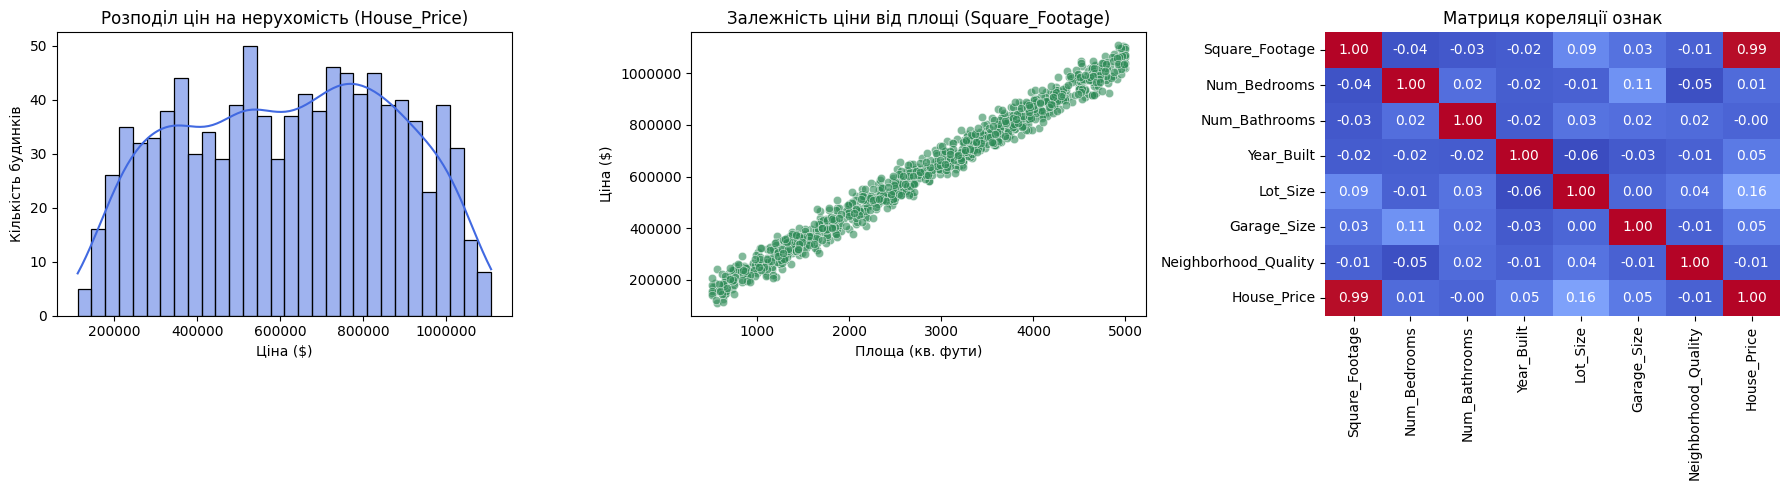


7. Порівняльна таблиця якості моделей регресії:


,Модель,MAE ($),MSE,RMSE ($),R2
1,Linear Regression,"8,174.58","101,434,798.51","10,071.48",0.9984
2,Lasso Regression,"8,174.75","101,436,558.18","10,071.57",0.9984
3,Ridge Regression,"8,241.59","102,480,990.01","10,123.29",0.9984
4,Gradient Boosting,"12,305.22","224,965,597.85","14,998.85",0.9965
5,Random Forest,"16,114.29","394,131,747.45","19,852.75",0.9939
6,Decision Tree,"24,084.46","969,600,136.06","31,138.40",0.9850



8. Виконується підбір гіперпараметрів для Random Forest (GridSearchCV)...
Найкращі параметри: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Показники Random Forest після тюнінгу:
  MAE:  $16,035.17
  RMSE: $19,678.14
  R2:   0.9940


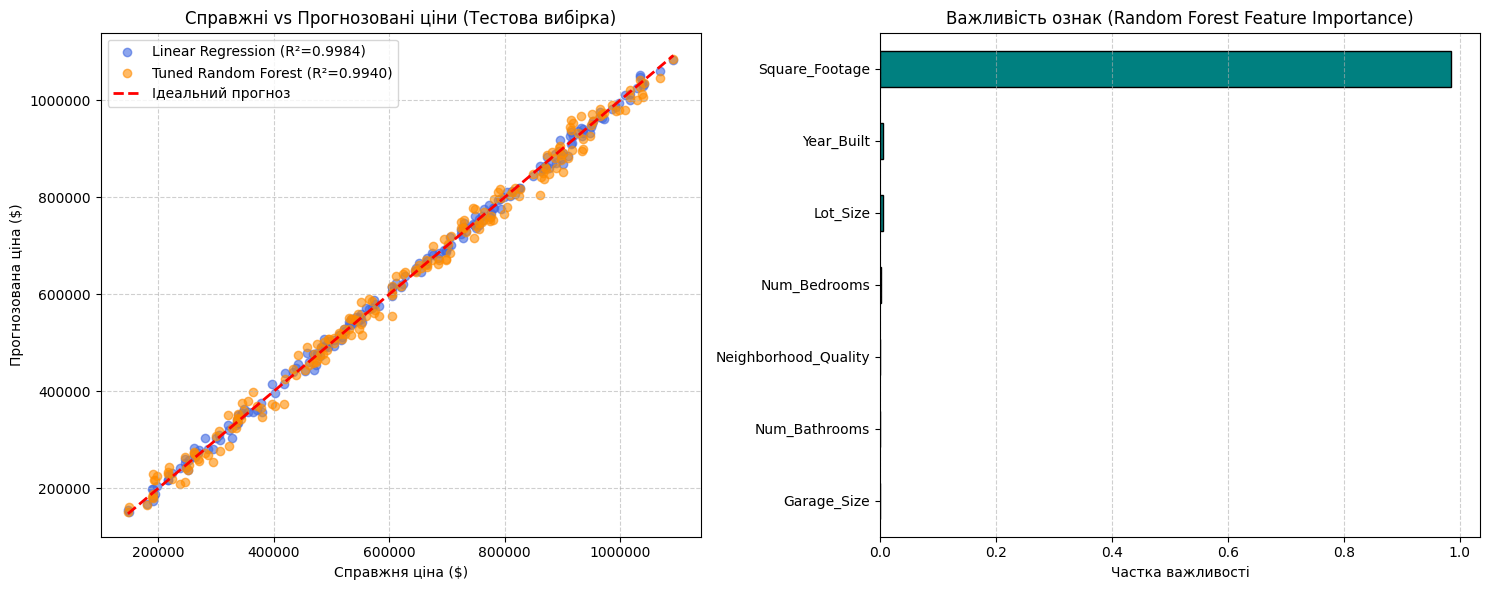

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Налаштовуємо формат виведення чисел (без наукового формату e+05, з роздільниками тисяч)
pd.options.display.float_format = '{:,.2f}'.format

# --- 1. Завантаження та первинний аналіз даних (EDA) ---
df = pd.read_csv('/house_price_regression_dataset.csv')

# Робимо нумерацію рядків з 1 для зручності
df.index = df.index + 1

print("1. Перші 5 рядків датасету:")
display(df.head())

print(f"\n2. Розмір датасету: рядків — {df.shape[0]}, стовпців — {df.shape[1]}")

print("\n3. Перевірка пропущених значень:")
print(df.isnull().sum())

print(f"\n4. Кількість дублікатів: {df.duplicated().sum()}")

print("\n5. Описова статистика датасету:")
display(df.describe())

# --- 2. Візуалізація даних та кореляції ---
corr_matrix = df.corr()
print("\n6. Кореляція ознак із цільовою змінною (House_Price):")
display(corr_matrix[['House_Price']].sort_values(by='House_Price', ascending=False).style.format("{:.4f}"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Графік 1: Розподіл цільової змінної
sns.histplot(df['House_Price'], bins=30, kde=True, color='royalblue', ax=axes[0])
axes[0].set_title('Розподіл цін на нерухомість (House_Price)')
axes[0].set_xlabel('Ціна ($)')
axes[0].set_ylabel('Кількість будинків')
axes[0].ticklabel_format(style='plain', axis='x')

# Графік 2: Залежність ціни від площі
sns.scatterplot(data=df, x='Square_Footage', y='House_Price', alpha=0.6, color='seagreen', ax=axes[1])
axes[1].set_title('Залежність ціни від площі (Square_Footage)')
axes[1].set_xlabel('Площа (кв. фути)')
axes[1].set_ylabel('Ціна ($)')
axes[1].ticklabel_format(style='plain', axis='y')

# Графік 3: Теплова карта кореляції
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=False, ax=axes[2])
axes[2].set_title('Матриця кореляції ознак')

plt.tight_layout()
plt.show()

# --- 3. Підготовка даних та побудова моделей регресії ---
X = df.drop('House_Price', axis=1)
y = df['House_Price']

# Розділення на тренувальну (80%) і тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Масштабування ознак для лінійних моделей
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

results = []
for name, model in models.items():
    if 'Regression' in name:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)

    results.append({
        'Модель': name,
        'MAE ($)': mae,
        'MSE': mse,
        'RMSE ($)': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1

print("\n7. Порівняльна таблиця якості моделей регресії:")
display(results_df.style.format({
    'MAE ($)': '{:,.2f}',
    'MSE': '{:,.2f}',
    'RMSE ($)': '{:,.2f}',
    'R2': '{:.4f}'
}))

# --- 4. Підбір гіперпараметрів для Random Forest ---
print("\n8. Виконується підбір гіперпараметрів для Random Forest (GridSearchCV)...")

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
best_preds = best_rf.predict(X_test)

print(f"Найкращі параметри: {grid_search.best_params_}")
print(f"Показники Random Forest після тюнінгу:")
print(f"  MAE:  ${mean_absolute_error(y_test, best_preds):,.2f}")
print(f"  RMSE: ${np.sqrt(mean_squared_error(y_test, best_preds)):,.2f}")
print(f"  R2:   {r2_score(y_test, best_preds):.4f}")

# --- 5. Візуалізація прогнозів та важливості ознак ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Порівняння справжніх та прогнозованих значень
lr_preds = models['Linear Regression'].predict(X_test_scaled)
axes[0].scatter(y_test, lr_preds, alpha=0.6, label='Linear Regression (R²=0.9984)', color='royalblue')
axes[0].scatter(y_test, best_preds, alpha=0.6, label='Tuned Random Forest (R²=0.9940)', color='darkorange')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ідеальний прогноз')
axes[0].set_title('Справжні vs Прогнозовані ціни (Тестова вибірка)')
axes[0].set_xlabel('Справжня ціна ($)')
axes[0].set_ylabel('Прогнозована ціна ($)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].ticklabel_format(style='plain')

# Важливість ознак у Random Forest
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', color='teal', edgecolor='black', ax=axes[1])
axes[1].set_title('Важливість ознак (Random Forest Feature Importance)')
axes[1].set_xlabel('Частка важливості')
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()